Task 1, morphological operations on a new image

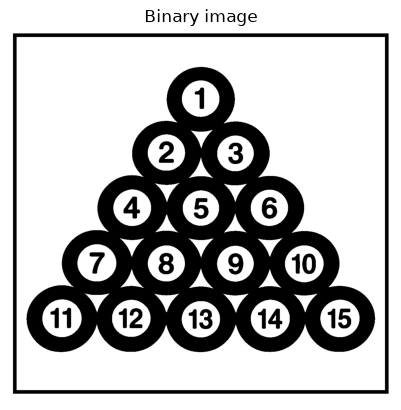

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'images9/Balls.png'   

img = cv2.imread(imgFile, 0)
assert img is not None, "Image not found - check the file name/path"

_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)



plt.imshow(binary, 'gray'); plt.title('Binary image'); plt.axis('off'); plt.show()


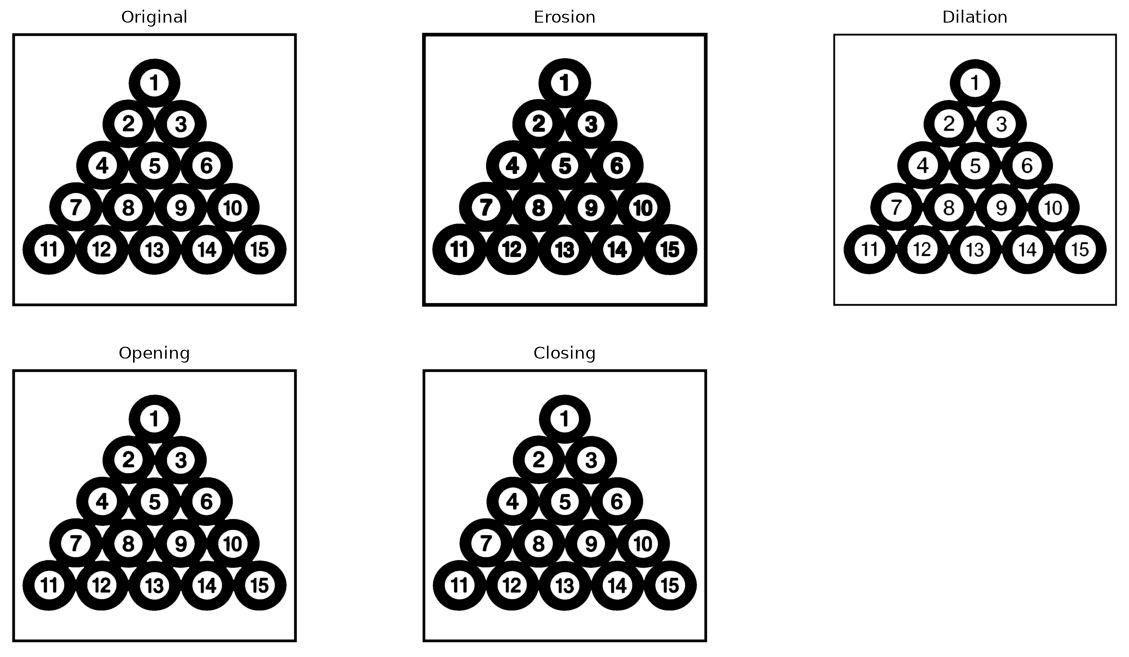

In [2]:
kernel = np.ones((5, 5), np.uint8)

eroded  = cv2.erode(binary, kernel, iterations=1)
dilated = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

titles = ['Original', 'Erosion', 'Dilation', 'Opening', 'Closing']
images = [binary, eroded, dilated, opening, closing]

plt.figure(figsize=(15, 8))
for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.axis('off')
plt.show()

Erosion shrinks the white objects and removes small specks.
Dilation grows the objects and fills small holes.
Opening (erode then dilate) removes small noise while keeping object size.
Closing (dilate then erode) fills small gaps and holes.

Task 2, structuring element shapes and sizes

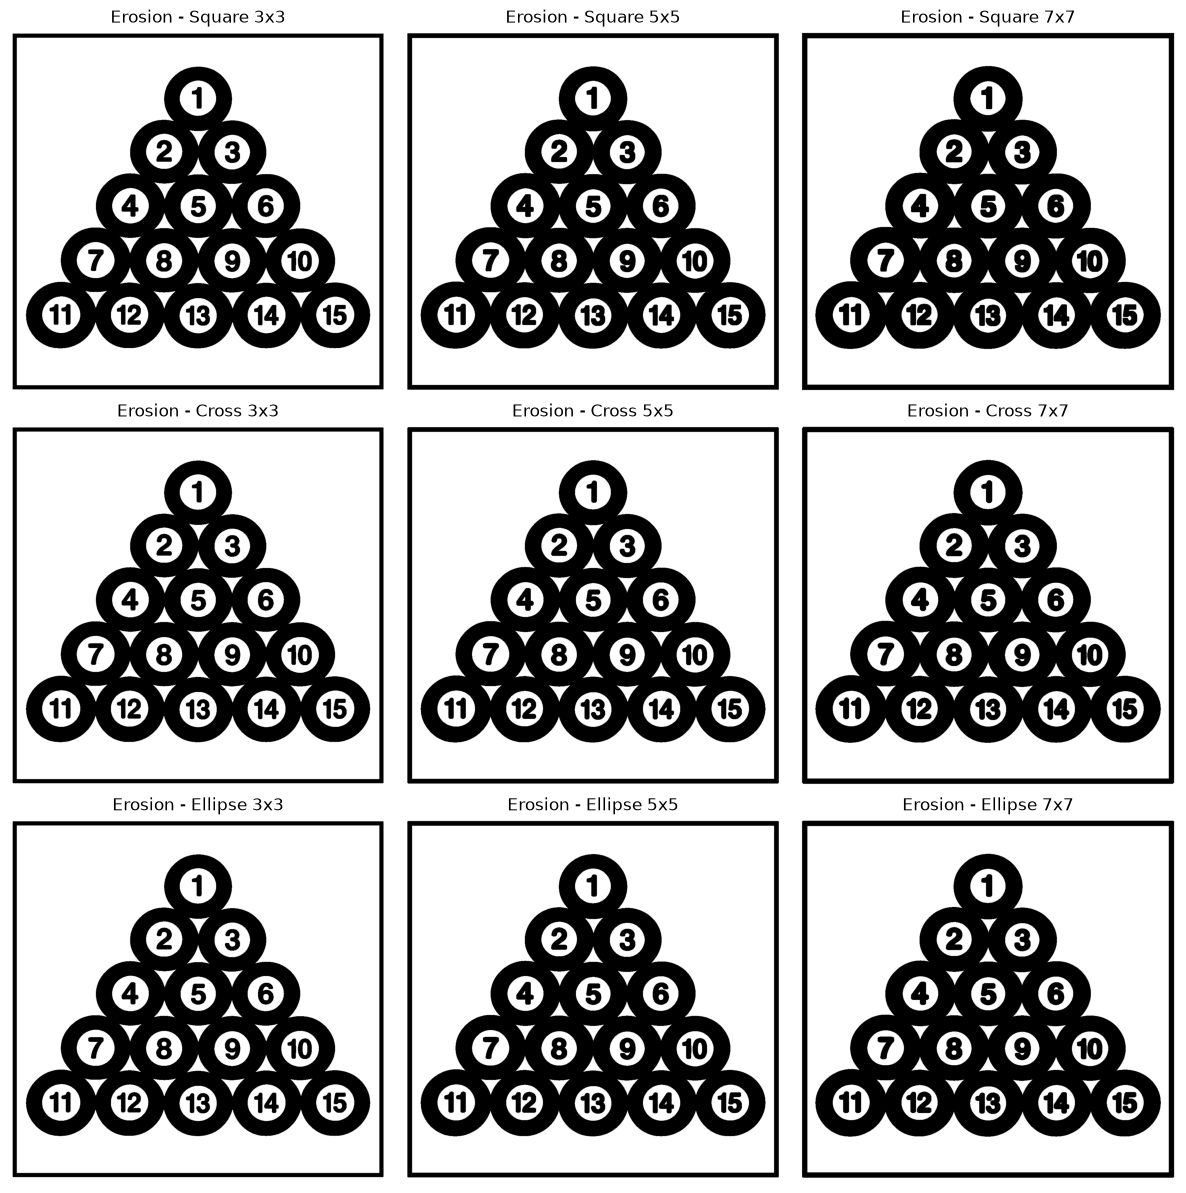

In [3]:
shapes = {'Square': cv2.MORPH_RECT,
          'Cross': cv2.MORPH_CROSS,
          'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]

plt.figure(figsize=(12, 12))
idx = 1
for name, shape in shapes.items():
    for s in sizes:
        k = cv2.getStructuringElement(shape, (s, s))
        result = cv2.erode(binary, k, iterations=1)
        plt.subplot(3, 3, idx)
        plt.imshow(result, 'gray')
        plt.title(f'Erosion - {name} {s}x{s}')
        plt.axis('off')
        idx += 1
plt.tight_layout()
plt.show()

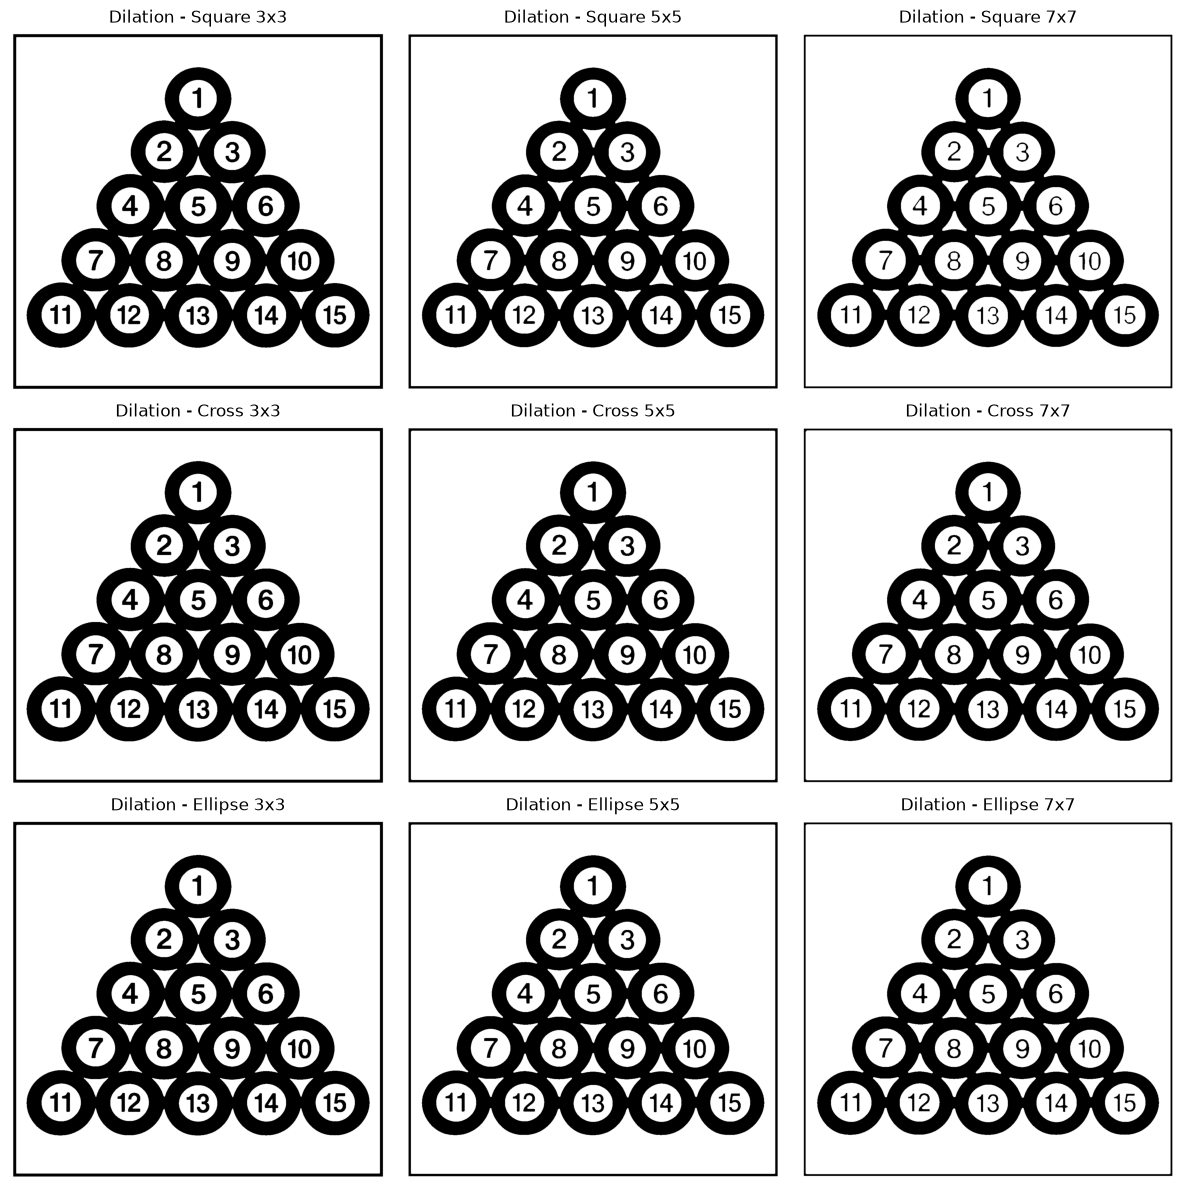

In [4]:
shapes = {'Square': cv2.MORPH_RECT,
          'Cross': cv2.MORPH_CROSS,
          'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]

plt.figure(figsize=(12, 12))
idx = 1
for name, shape in shapes.items():
    for s in sizes:
        k = cv2.getStructuringElement(shape, (s, s))
        result = cv2.dilate(binary, k, iterations=1)
        plt.subplot(3, 3, idx)
        plt.imshow(result, 'gray')
        plt.title(f'Dilation - {name} {s}x{s}')
        plt.axis('off')
        idx += 1
plt.tight_layout()
plt.show()

In [5]:
for name, shape in shapes.items():
    print(name, '\n', cv2.getStructuringElement(shape, (7, 7)), '\n')

Square 
 [[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]] 

Cross 
 [[0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [1 1 1 1 1 1 1]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]] 

Ellipse 
 [[0 0 0 1 0 0 0]
 [0 1 1 1 1 1 0]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 0 0 1 0 0 0]] 



Larger kernels give a stronger effect, with more shrinking or growing.
A square kernel affects the diagonal corners more, so shapes look boxier.
A cross affects only horizontal and vertical neighbours, so it’s the mildest effect.
An ellipse keeps round objects like balls round, so it’s the most natural choice for them.